# Project 08: Anomaly Detection with No Labels

**Original statement (verbatim from LAB_Projects_ML.pdf):**

You receive system log data with unknown anomalies. Task: Implement at least two unsupervised methods; Compare detection overlap; Validate anomalies using proxy metrics

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Without labels, 'anomaly' means 'unusual in feature space'. This notebook compares two unsupervised detectors and validates their flags with proxy statistics (extremeness, not a hidden label).

## Part 1 — Introduction

THERE ARE NO SYSTEM LOGS AND NO ANOMALY LABELS IN THIS FILE. Methods below are trained without labels on weather features only; the label column is used ONLY afterwards as a descriptive check, never as training ground truth, and no anomaly is claimed to be a true fault.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Two unsupervised detectors

In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
df=df_full.sample(n=10000, random_state=42)
Xs=StandardScaler().fit_transform(df[FEATURES])
iso=IsolationForest(contamination=0.05, random_state=42, n_jobs=-1); pred_iso=iso.fit_predict(Xs); df["iso_anomaly"]=(pred_iso==-1)
print("IsolationForest anomaly rate:", round(df["iso_anomaly"].mean(),4))
# LOF is slower: use 5000 rows
sub=df.iloc[:5000].copy(); Xsub=StandardScaler().fit_transform(sub[FEATURES])
lof=LocalOutlierFactor(n_neighbors=20, contamination=0.05); pred_lof=lof.fit_predict(Xsub); sub["lof_anomaly"]=(pred_lof==-1)
merged=sub.copy(); merged["iso_anomaly"]=df.iloc[:5000]["iso_anomaly"].values
overlap=int((merged["iso_anomaly"] & merged["lof_anomaly"]).sum()); union=int((merged["iso_anomaly"] | merged["lof_anomaly"]).sum())
print("LOF anomaly rate (5000 rows):", round(sub["lof_anomaly"].mean(),4))
print(f"Overlap: both flag {overlap} rows; either flags {union}; Jaccard = {overlap/max(1,union):.4f}")

IsolationForest anomaly rate: 0.05
LOF anomaly rate (5000 rows): 0.05
Overlap: both flag 112 rows; either flags 363; Jaccard = 0.3085


## Part 4 — Proxy validation and plots

Pressure normal mean: 1011.568 iso-anomaly mean: 1008.816
global_radiation normal mean: 1.32 iso-anomaly mean: 1.398
temp_mean(c) normal mean: 13.002 iso-anomaly mean: 9.154
temp_min(c) normal mean: 9.032 iso-anomaly mean: 4.468
temp_max(c) normal mean: 17.239 iso-anomaly mean: 13.571
Wind_Speed normal mean: 11.743 iso-anomaly mean: 16.315
Wind_Bearing normal mean: 193.16 iso-anomaly mean: 175.347
Descriptive only — share of each original label among IsolationForest anomalies (NOT accuracy):
normalized_label
1    30.22
0    24.44
2    24.00
3    21.33
Share among normal rows:
normalized_label
0    45.91
1    28.27
2    16.50
3     9.32


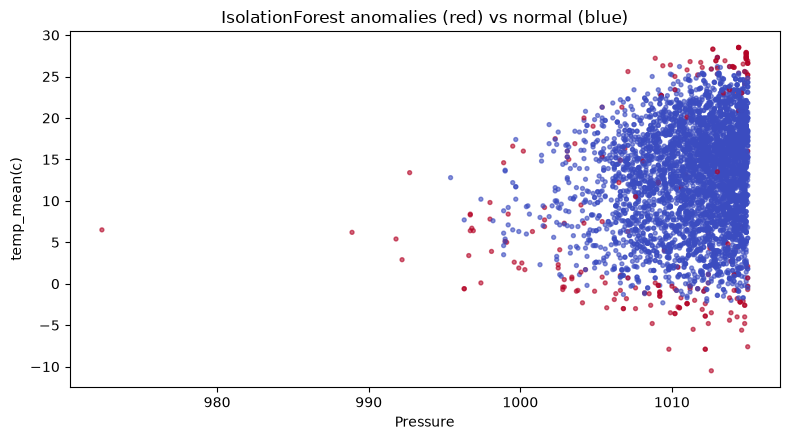

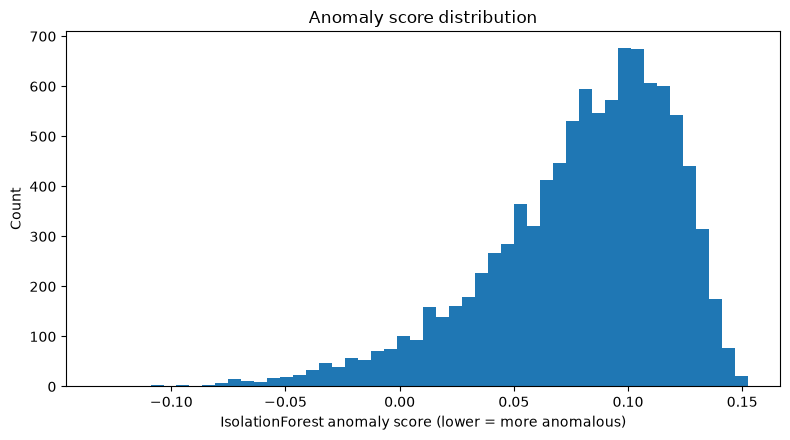

In [3]:
for c in FEATURES:
    print(c, "normal mean:", round(merged.loc[~merged["iso_anomaly"],c].mean(),3), "iso-anomaly mean:", round(merged.loc[merged["iso_anomaly"],c].mean(),3))
print("Descriptive only — share of each original label among IsolationForest anomalies (NOT accuracy):")
print((merged[merged["iso_anomaly"]][TARGET].value_counts(normalize=True)*100).round(2).to_string())
print("Share among normal rows:")
print((merged[~merged["iso_anomaly"]][TARGET].value_counts(normalize=True)*100).round(2).to_string())
plt.figure(figsize=(8,4.5)); plt.scatter(merged["Pressure"], merged["temp_mean(c)"], c=merged["iso_anomaly"], cmap="coolwarm", s=8, alpha=0.6); plt.xlabel("Pressure"); plt.ylabel("temp_mean(c)"); plt.title("IsolationForest anomalies (red) vs normal (blue)"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,4.5)); plt.hist(iso.decision_function(Xs), bins=50); plt.xlabel("IsolationForest anomaly score (lower = more anomalous)"); plt.ylabel("Count"); plt.title("Anomaly score distribution"); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("VALIDATION BY PROXY: Anomalies should be more extreme on several features and should be flagged by both methods more often than chance (Jaccard above). Agreement alone does not prove a row is faulty; in operations, flagged rows would be reviewed by a domain expert before any action.")

VALIDATION BY PROXY: Anomalies should be more extreme on several features and should be flagged by both methods more often than chance (Jaccard above). Agreement alone does not prove a row is faulty; in operations, flagged rows would be reviewed by a domain expert before any action.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.